# Аналіз даних: клавіатурний почерок

**Що ми робимо.** У нас є таблиця `features.csv`: один рядок = одна спроба набрати фразу `SS123+`.
Хочемо подивитися на дані й відповісти на питання: **чи справді люди друкують по-різному?**

Кроки: 1) завантажити дані, 2) порахувати спроби, 3) прибрати дивні спроби, 4) намалювати графіки, 5) зробити висновок.

Щоб запустити все: меню **Run → Run All**. Якщо додали нові дані, спочатку виконайте `python features.py`.

## 1. Завантажуємо дані

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df = pd.read_csv("data/features.csv")

df["user"] = "u" + df["user_id"].astype("category").cat.codes.astype(str)
df = df.drop(columns="user_id")

print("Спроб:", len(df))
print("Учасників:", df["user"].nunique())
df.head()

Спроб: 1080
Учасників: 65


,session_id,attempt_id,total_ms,speed_cps,backspace_count,error_count,dwell_1,dwell_2,dwell_3,dwell_4,...,uu_5,dwell_mean,dwell_median,dwell_std,dwell_cv,ud_mean,ud_median,ud_std,ud_cv,user
0,yu3pndz4mweoguwt,016tv8wemweokgv2,1632.4,3.675570,0,0,62.8,79.7,77.5,79.6,...,839.4,77.200000,78.90,7.585513,0.098258,233.84,106.1,294.965656,1.261399,u57
1,qpe9g14kmwewyejb,01uu32tnmwexa37d,1600.0,3.750000,0,0,95.7,96.0,112.1,95.7,...,512.5,117.183333,104.05,28.031227,0.239208,179.38,136.3,107.259578,0.597946,u47
2,y1n0hg2emweobiaa,045l13btmweok7dk,1935.6,3.099814,0,0,79.7,72.1,128.0,87.9,...,991.9,82.600000,75.90,24.098133,0.291745,288.00,144.0,365.264842,1.268281,u46
3,dh61plnimwessf8q,04kbry2rmwestxpu,1330.0,4.511278,0,0,76.2,94.6,89.2,78.7,...,377.8,78.633333,83.35,17.802996,0.226405,171.64,141.2,99.536842,0.579916,u60
4,0eo62bq0mwestj3e,04woh0n3mweswgbu,1248.0,4.807692,0,0,83.3,91.8,153.7,82.2,...,499.5,101.016667,93.65,26.686582,0.264180,128.38,114.1,170.327617,1.326746,u53


## 2. Скільки спроб у кожного учасника

За технічним завданням потрібно **не менше 30 спроб** на людину.

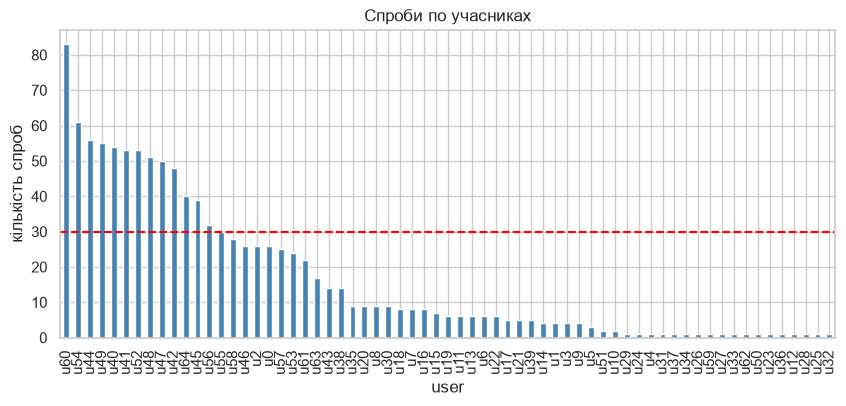

Найбільше спроб в однієї людини: 83
Учасників, у яких 30 і більше спроб: 14


In [2]:
counts = df["user"].value_counts()

plt.figure(figsize=(10, 4))
counts.plot(kind="bar", color="steelblue")
plt.axhline(30, color="red", linestyle="--")   # червона лінія: потрібно 30
plt.title("Спроби по учасниках")
plt.ylabel("кількість спроб")
plt.savefig("reports/eda/1_спроби.png", dpi=150, bbox_inches="tight")
plt.show()

print("Найбільше спроб в однієї людини:", counts.max())
print("Учасників, у яких 30 і більше спроб:", (counts >= 30).sum())

## 3. Чи є пропуски в таблиці

In [3]:
print("Порожніх клітинок:", df.isna().sum().sum())

Порожніх клітинок: 0


## 4. Прибираємо дивні спроби (викиди)

Іноді людина відволіклась, і спроба тривала 15 секунд замість 3. Такі спроби псують картину.

Правило (метод IQR):
- Q1 і Q3 це «нижня» і «верхня» чверті часу набору;
- IQR = Q3 − Q1;
- дивною вважаємо спробу, час якої менший за `Q1 − 1.5·IQR` або більший за `Q3 + 1.5·IQR`.

In [4]:
q1 = df["total_ms"].quantile(0.25)
q3 = df["total_ms"].quantile(0.75)
iqr = q3 - q1

low = q1 - 1.5 * iqr
high = q3 + 1.5 * iqr

clean = df[(df["total_ms"] >= low) & (df["total_ms"] <= high)]

print(f"Нормальний час набору: від {low:.0f} до {high:.0f} мс")
print(f"Видалено дивних спроб: {len(df) - len(clean)} із {len(df)}")

clean.to_csv("data/features_clean.csv", index=False)   # зберігаємо чисту таблицю

Нормальний час набору: від 379 до 3698 мс
Видалено дивних спроб: 76 із 1080


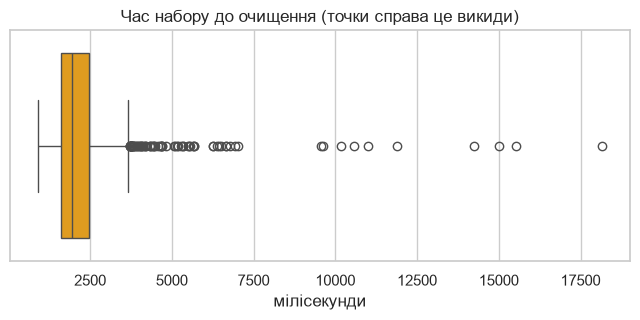

In [5]:
plt.figure(figsize=(8, 3))
sns.boxplot(x=df["total_ms"], color="orange")
plt.title("Час набору до очищення (точки справа це викиди)")
plt.xlabel("мілісекунди")
plt.savefig("reports/eda/2_викиди.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Скільки людина тримає кожну клавішу (dwell)

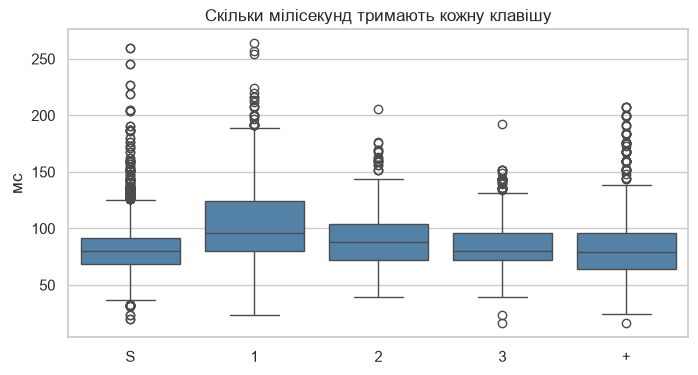

In [6]:
keys = ["S", "S", "1", "2", "3", "+"]
dwell = clean[["dwell_1", "dwell_2", "dwell_3", "dwell_4", "dwell_5", "dwell_6"]]
dwell.columns = keys

plt.figure(figsize=(8, 4))
sns.boxplot(data=dwell, color="steelblue")
plt.title("Скільки мілісекунд тримають кожну клавішу")
plt.ylabel("мс")
plt.savefig("reports/eda/3_dwell.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Чи відрізняються люди між собою

Беремо тільки учасників, у яких хоча б 5 спроб, і порівнюємо **середній час утримання клавіші**.
Якщо «коробки» розташовані на різній висоті, то люди друкують по-різному.

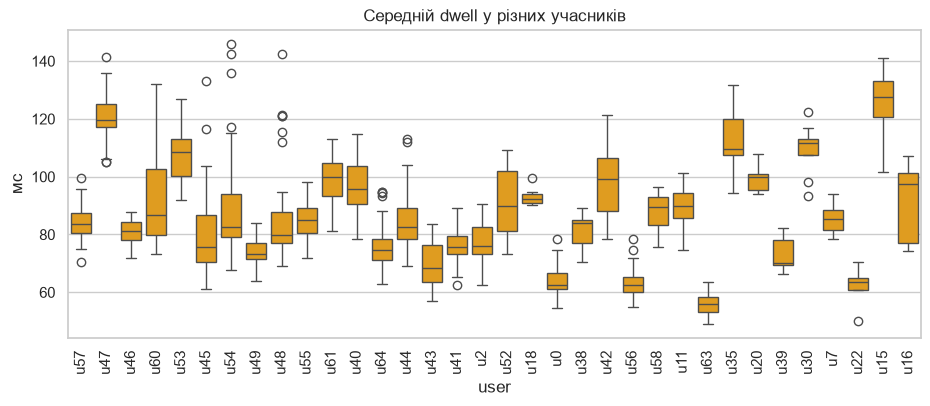

In [7]:
many = clean["user"].value_counts()
many = many[many >= 5].index
part = clean[clean["user"].isin(many)]

plt.figure(figsize=(11, 4))
sns.boxplot(data=part, x="user", y="dwell_mean", color="orange")
plt.title("Середній dwell у різних учасників")
plt.ylabel("мс")
plt.xticks(rotation=90)
plt.savefig("reports/eda/4_люди.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Які ознаки схожі між собою (кореляція)

Число від −1 до 1: біля 1 означає «одна росте, і друга росте», біля 0 означає «ніяк не пов'язані».

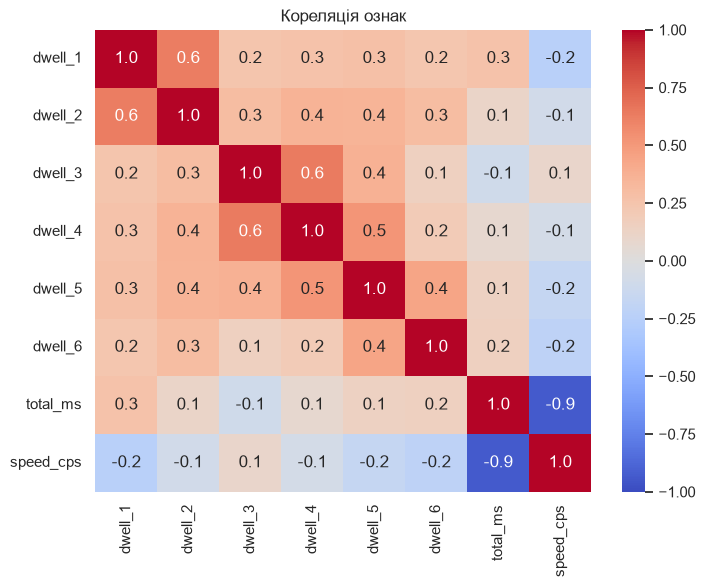

In [8]:
cols = ["dwell_1", "dwell_2", "dwell_3", "dwell_4", "dwell_5", "dwell_6", "total_ms", "speed_cps"]

plt.figure(figsize=(8, 6))
sns.heatmap(clean[cols].corr(), annot=True, fmt=".1f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Кореляція ознак")
plt.savefig("reports/eda/5_кореляція.png", dpi=150, bbox_inches="tight")
plt.show()